# Assignment 2 – Zero-Shot Image Classification with Transformers

In this assignment, you will apply a pre-trained vision–language transformer (e.g. CLIP) to perform **zero-shot** classification on the Fashion-MNIST dataset—classifying each image without any task-specific training. You will build on the concepts from Assignment 1 by comparing this “off-the-shelf” approach to the CNN you previously trained.

You will:
1. **Load** the Fashion-MNIST images using PyTorch instead of Keras.
2. **Run a zero-shot baseline** with simple text prompts to set a performance reference.
3. **Engineer improved prompts** and measure the resulting accuracy gains.
4. **Visualise image embeddings** with UMAP to inspect class separability.
5. **Conduct one mini-experiment** of your choice.
6. **Summarise findings** and reflect on strengths and weaknesses of zero-shot transformers versus a trained CNN.

# 1. Loading the Fashion-MNIST Dataset

As in assignment 1, we'll load the Fashion-MNIST dataset, but this time using `torchvision.datasets` to ensure compatibility with the `transformers` library. We will also load our model and processor from the `transformers` library.

The transformers library allows us to use pre-trained models like CLIP, which can perform zero-shot classification by leveraging the text prompts we provide. There are two key objects we will use: the `CLIPModel` for the model itself and the `CLIPProcessor` for preparing our images and text prompts.

Since we are not actually training a model in this assignment, we will set the CLIP model to evaluation mode. If the model is designed to utilize features like dropout or batch normalization, setting it to evaluation mode ensures that these features behave correctly during inference (prediction). Setting the model to evaluaton mode also tells PyTorch that we don't have to compute gradients, which can save memory and speed up inference.

In order to speed up processing, we will also move the model to an "accelerator" if available. This is typically a GPU, but modern MacBooks also have an "Apple Silicon" accelerator that can be used for inference, called MPS (Metal Performance Shaders). If you are using a MacBook with Apple Silicon, you can use the MPS device for faster processing.

In [6]:
# Uncomment and run if required
#!pip install transformers torchvision torch accelerate

In [7]:
from transformers import CLIPModel, CLIPProcessor
import torch

clip_model_name = "openai/clip-vit-base-patch32"
clip_model     = CLIPModel.from_pretrained(clip_model_name)
clip_processor = CLIPProcessor.from_pretrained(clip_model_name, use_fast=False)

# Set model to evaluation mode, as we are not training it
clip_model.eval()

# Check for accelerators
device = "cpu" # Default to CPU
if torch.cuda.is_available():
    device = "cuda" # Use GPU if available
elif torch.backends.mps.is_available():
    device = "mps"

clip_model.to(device)

print(f"Using device: {device}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


Using device: cpu


Now we are ready to load the testing set from Fashion-MNIST. We will use the `torchvision.datasets.FashionMNIST` class to load the dataset. We do not need to apply any transformations to the images, as the `CLIPProcessor` ensures any input images are in the format that the model is trained on.

You should:

- [ ] Use the `torchvision.datasets.FashionMNIST` class to load the *test* split of the dataset. Documentation is available [here](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html).
- [ ] Create a PyTorch `DataLoader` to iterate over the dataset in batches. Use a batch size of 16 and set `shuffle=True` to randomise the order of the images. You will also need to supply the provided `collate_clip` function to the `DataLoader collate_fn` argument to ensure the images are processed correctly. Documentation for `DataLoader` is available [here](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader).

In [8]:
# Installing any missing packages in the environment before continuing
# If needed, uncomment in a notebook cell and run once:
# %pip install torch torchvision transformers scikit-learn matplotlib umap-learn seaborn tqdm

import random
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import FashionMNIST
from torchvision.transforms import ToTensor, ToPILImage
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tqdm.auto import tqdm

to_pil = ToPILImage()

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 64 if DEVICE == "cuda" else 32
MAX_TEST_SAMPLES = None  # use e.g. 2000 for a quick run; None uses all 10,000 test images
MODEL_ID = "openai/clip-vit-base-patch32"

print(f"Device: {DEVICE}; batch size: {BATCH_SIZE}")

Device: cpu; batch size: 32


In [ ]:
# Load the FashionMNIST and CLIP model.Fashion-MNIST images are grayscale, 28×28 pixels. CLIP expects RGB image inputs
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

train_dataset = FashionMNIST(root="./data", train=True, download=True, transform=ToTensor())
test_dataset = FashionMNIST(root="./data", train=False, download=True, transform=ToTensor())

if MAX_TEST_SAMPLES is not None:
    test_dataset = Subset(test_dataset, range(min(MAX_TEST_SAMPLES, len(test_dataset))))

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

processor = CLIPProcessor.from_pretrained(MODEL_ID)
model = CLIPModel.from_pretrained(MODEL_ID).to(DEVICE)
model.eval()
print(f"Test images: {len(test_dataset)}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Test images: 10000


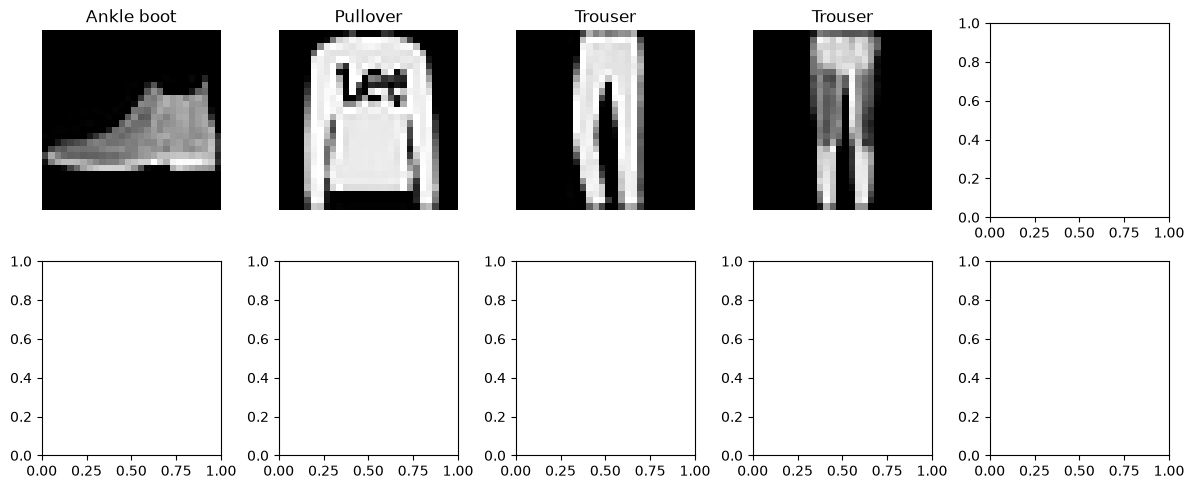

In [ ]:
# Inspecting few Images from the dataset
images, labels = next(iter(test_loader))
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, image, label in zip(axes.flat, images[:10], labels[:10]):
    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(class_names[int(label)])
    ax.axis("off")
plt.tight_layout()

In [ ]:
torch.set_num_threads(2)  # Try 2; use 1 if CPU usage is still too high

BATCH_SIZE = 4  # If RAM allows, try 8 for faster processing

baseline_loader = DataLoader(
    test_loader.dataset,  # Keeps the same test data or subset
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
)

In [ ]:
# Zero-shot prediction helper

import gc
import numpy as np
import torch
from tqdm.auto import tqdm


def get_feature_tensor(output, feature_name):
    """Handle tensor outputs and common Transformers output objects."""
    if isinstance(output, torch.Tensor):
        return output

    feature = getattr(output, feature_name, None)
    if feature is not None:
        return feature

    pooler_output = getattr(output, "pooler_output", None)
    if pooler_output is not None:
        return pooler_output

    return output.last_hidden_state[:, 0, :]


@torch.inference_mode()
def predict_zero_shot(
    prompts_by_class,
    loader=test_loader,
    return_features=False,
):
    """Classify images in batches; optionally return image embeddings."""

    # Build and normalize one text embedding per prompt.
    prompts = [p for prompts in prompts_by_class for p in prompts]

    text_inputs = processor(
        text=prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
    ).to(DEVICE)

    text_features = get_feature_tensor(
        model.get_text_features(**text_inputs),
        "text_embeds",
    )
    text_features = torch.nn.functional.normalize(text_features, dim=-1)

    # Average prompts within each class.
    class_features = []
    start = 0

    for class_prompts in prompts_by_class:
        end = start + len(class_prompts)
        mean_feature = text_features[start:end].mean(dim=0)
        class_features.append(
            torch.nn.functional.normalize(mean_feature, dim=0)
        )
        start = end

    class_features = torch.stack(class_features)

    y_true = []
    y_pred = []
    all_features = [] if return_features else None

    for batch_images, batch_labels in tqdm(loader, desc="Classifying"):
        # Convert only this small batch to PIL, then prepare CLIP inputs.
        pil_images = [to_pil(img) for img in batch_images]

        image_inputs = processor(
            images=pil_images,
            return_tensors="pt",
        )

        pixel_values = image_inputs["pixel_values"].to(DEVICE)
        image_features = get_feature_tensor(
            model.get_image_features(pixel_values=pixel_values),
            "image_embeds",
        )
        image_features = torch.nn.functional.normalize(
            image_features,
            dim=-1,
        )

        # Compare with each class embedding.
        predictions = (100.0 * image_features @ class_features.T).argmax(dim=1)

        y_true.extend(batch_labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

        if return_features:
            # Half precision uses about half the memory for saved embeddings.
            all_features.append(
                image_features.cpu().to(torch.float16).numpy()
            )

        # Release batch temporaries before loading the next batch.
        del pil_images, image_inputs, pixel_values, image_features, predictions

    result = (np.asarray(y_true), np.asarray(y_pred))

    if return_features:
        features = np.concatenate(all_features, axis=0)
        del all_features
        gc.collect()
        return (*result, features)

    gc.collect()
    return result

In [ ]:
torch.set_num_threads(2)  # Try 2; use 1 if CPU usage is still too high

BATCH_SIZE = 4  # If RAM allows, try 8 for faster processing

baseline_loader = DataLoader(
    test_loader.dataset,  # Keeps the same test data or subset
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
)

In [ ]:
BATCH_SIZE = 4  # Try 8 if memory use is comfortable

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
)

In [ ]:
from torchvision.datasets import FashionMNIST
from torch.utils.data import DataLoader
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 2  # Increase to 4 if your laptop handles it comfortably

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

def collate_clip(batch):
    images, labels = zip(*batch)

    # Process just this small batch; keep pixel_values on CPU until inference.
    pixel_values = clip_processor(
        images=list(images),
        return_tensors="pt",
    )["pixel_values"]

    labels = torch.tensor(labels, dtype=torch.long)
    return pixel_values, labels

test_dataset = FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=None,  # Keep images as PIL for CLIPProcessor
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
    collate_fn=collate_clip,
)

If your code is correct, the following cell should show the first batch of images from the Fashion-MNIST dataset:

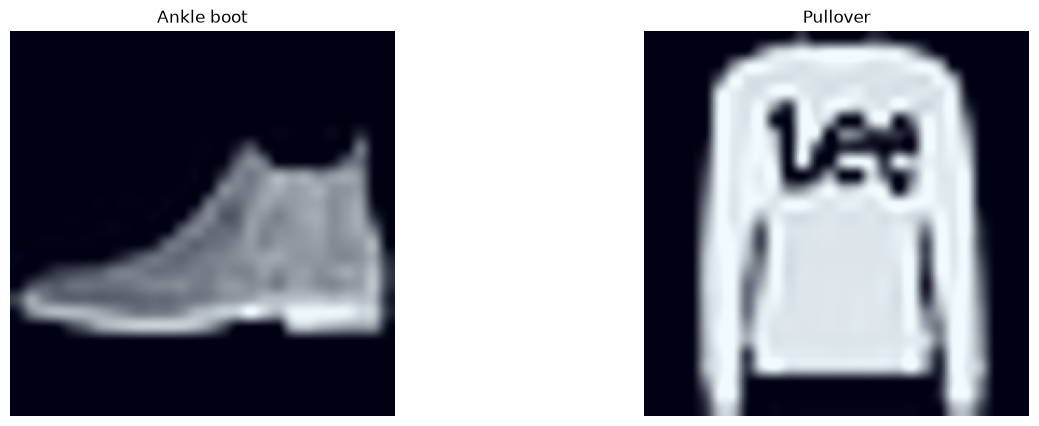

In [ ]:
import matplotlib.pyplot as plt

# Display the first batch of images from `test_loader`

def show_batch(loader):
    images, labels = next(iter(loader))
    images = images.cpu()  # Move images to CPU for plotting
    # Renormalize to [0, 1] for visualization
    images = (images - images.min()) / (images.max() - images.min())
    _, axes = plt.subplots(1, len(images), figsize=(15, 5))
    for ax, img, label in zip(axes, images, labels):
        ax.imshow(img.permute(1, 2, 0))
        ax.set_title(CLASS_NAMES[label.item()])
        ax.axis('off')
    plt.show()

show_batch(test_loader)

We’re now ready to run our zero-shot classification baseline!

# Brief Introduction to Zero-Shot Classification

In Assignment 1, we followed the typical machine-learning pipeline: we trained a CNN on the Fashion-MNIST dataset, using labelled examples to update the model’s weights. While effective, that approach requires a curated, task-specific training set—a luxury you don’t always have in practice.

Zero-shot classification flips the script.  A large vision–language model (VLM) such as **CLIP** is first pre-trained on hundreds of millions of image–text pairs scraped from the web.  Because it learns *joint* visual–textual embeddings, the model can later solve new tasks simply by “measuring” how similar an image is to a **text prompt** that describes each candidate class—without seeing a single task-labelled example.

**How it works**  
1. Feed an image through CLIP’s vision encoder → **image feature**.  
2. Feed a textual prompt (e.g. “a photo of a sandal”) through CLIP’s text encoder → **text feature**.  
3. Compute cosine similarity between the image feature and every class’s text feature.  
4. Pick the class whose prompt is most similar.

For our first attempt, we’ll use the bare class names as prompts, e.g.:

- "T-shirt/top"
- "Trouser"

### You should:

- [ ] Build embeddings: use the `get_text_embeddings` helper function to create text embeddings for the class names.
- [ ] Run inference: use the `get_image_embeddings` helper function to create image embeddings.
- [ ] Compute cosine similarity: complete and use the `get_cosine_similarity` helper function to compute the cosine similarity between the image and text embeddings.
- [ ] Make predictions: use the `get_predictions` helper function to get the predicted class for each image in the batch.

Note that for normalized vectors like the ones we are using, cosine similarity is equivalent to the dot product. This means we can use the handy formula `cosine_similarity = vector_a @ vector_b.T` to compute the similarity between the image and text embeddings.

In [ ]:
def get_text_embeddings(class_names: list[str]) -> torch.Tensor:
    """    Get text embeddings for the given class names using CLIP.
    Args:
        class_names (list[str]): List of class names to encode.
    Returns:
        torch.Tensor: Normalized text embeddings for the class names.
    """
    tokenized = clip_processor(text=class_names,
                               padding=True,
                               return_tensors="pt").to(device)
    
    with torch.no_grad():
        text_embeddings = clip_model.get_text_features(**tokenized)

    text_feats = text_embeddings / text_embeddings.norm(dim=-1, keepdim=True)

    return text_feats

def get_image_embeddings(images: torch.Tensor) -> torch.Tensor:
    """    Get image embeddings for the given images using CLIP.
    Args:
        images (torch.Tensor): Batch of images to encode.
    Returns:
        torch.Tensor: Normalized image embeddings for the images.
    """
    with torch.no_grad():
        image_embeddings = clip_model.get_image_features(pixel_values=images)

    image_feats = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True)

    return image_feats

In [ ]:
import numpy as np

def get_cosine_similarity(image_feats: torch.Tensor, text_feats: torch.Tensor) -> np.ndarray:
    """
    Compute cosine similarity between image features and text features.
    Args:
        image_feats (torch.Tensor): Image features of shape (N, D).
        text_feats (torch.Tensor): Text features of shape (M, D).
    Returns:
        numpy.ndarray: Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    """
    image_feats = image_feats.cpu()  # Ensure image features are on CPU
    text_feats = text_feats.cpu()    # Ensure text features are on CPU

    # Compute cosine similarity, which is the dot product of normalized vectors
    return # Complete

def get_predictions(similarity: np.ndarray) -> np.ndarray:
    """
    Get predictions based on cosine similarity scores.
    Args:
        similarity (numpy.ndarray): Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    Returns:
        numpy.ndarray: Predicted class indices for each image, shape (N,).
    """
    # Get the index of the maximum similarity for each image
    return # Complete

With these functions complete, you are ready to run the zero-shot classification baseline. Complete the code to follow these steps:

- [ ] Build text embeddings for the class names using the `get_text_embeddings` function (this only needs to be done once).
- [ ] For each batch of images:
    - [ ] Get image embeddings using the `get_image_embeddings` function.
    - [ ] Compute cosine similarity between the image and text embeddings using the `get_cosine_similarity` function.
    - [ ] Save the predictions so that we can build a confusion matrix later.
- [ ] Report the accuracy of the predictions and the confusion matrix using the `accuracy_score` and `confusion_matrix` functions from `sklearn.metrics`.

In [ ]:
import torch.nn.functional as F

device = next(model.parameters()).device

@torch.inference_mode()
def get_image_embeddings(pixel_values):
    pixel_values = pixel_values.to(device)

    vision_output = model.vision_model(pixel_values=pixel_values)
    embeddings = model.visual_projection(vision_output.pooler_output)

    return F.normalize(embeddings, p=2, dim=-1)


@torch.inference_mode()
def get_text_embeddings(class_names):
    inputs = clip_processor(
        text=list(class_names),
        return_tensors="pt",
        padding=True,
        truncation=True,
    )

    text_output = model.text_model(
        input_ids=inputs["input_ids"].to(device),
        attention_mask=inputs["attention_mask"].to(device),
    )
    embeddings = model.text_projection(text_output.pooler_output)

    return F.normalize(embeddings, p=2, dim=-1)


def get_cosine_similarity(image_embeddings, text_embeddings):
    # Both inputs should be normalized tensors with matching embedding dimensions.
    return image_embeddings @ text_embeddings.T

In [ ]:
text_embeddings = get_text_embeddings(CLASS_NAMES)

for pixel_values, labels in test_loader:
    image_embeddings = get_image_embeddings(pixel_values)
    similarities = get_cosine_similarity(image_embeddings, text_embeddings)
    predictions = similarities.argmax(dim=1)

    y_true.extend(labels.tolist())
    y_pred.extend(predictions.cpu().tolist())

Accuracy: 0.6240 (62.40%)
Confusion matrix:
[[769  25   2  95  18  14  19   0  58   0]
 [  0 931   0   5   5  56   0   0   3   0]
 [415  25 306   6 174   7   4   0  63   0]
 [ 56  87   2 504 216  77   2   1  53   2]
 [ 74  19 143   9 690   6   1   0  58   0]
 [  0  31   3   0   1 393   0 414  17 141]
 [338  29  29  79 394  20  42   0  68   1]
 [  0   0   0   0   0  49   0 950   0   1]
 [  0  14   3   0   1  19   0   5 958   0]
 [  0   0   0   0   0   5   0 297   1 697]]


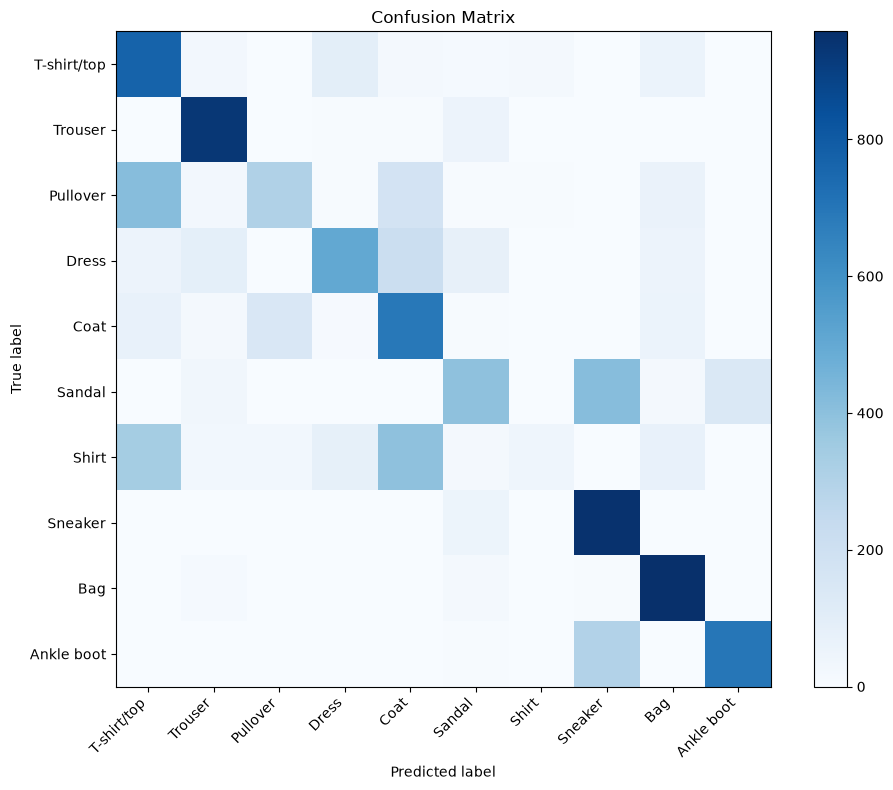

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_true, y_pred = [], []

# Compute text embeddings once, before processing image batches.
text_embeddings = get_text_embeddings(CLASS_NAMES)

with torch.inference_mode():
    for pixel_values, labels in test_loader:
        image_embeddings = get_image_embeddings(pixel_values)
        similarities = get_cosine_similarity(
            image_embeddings,
            text_embeddings,
        )
        predictions = similarities.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.detach().cpu().tolist())

# Report accuracy and confusion matrix.
accuracy = accuracy_score(y_true, y_pred)
print(f"Accuracy: {accuracy:.4f} ({accuracy:.2%})")

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(CLASS_NAMES)),
)
print("Confusion matrix:")
print(cm)


def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(len(class_names)),
    )

    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    plt.title("Confusion Matrix")
    plt.colorbar()

    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45, ha="right")
    plt.yticks(tick_marks, class_names)
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.tight_layout()
    plt.show()


plot_confusion_matrix(y_true, y_pred, CLASS_NAMES)

Reflection: Consider the results. How does the performance of this zero-shot baseline compare to the CNN you trained in Assignment 1? What are the strengths and weaknesses of this approach?

## Improving Zero-Shot Classification with Prompt Engineering

In the previous section, we directly used the class names as text prompts for zero-shot classification. However, we can often improve performance by crafting more descriptive prompts that better capture the visual characteristics of each class. For example, instead of just "T-shirt/top", we could use "a photo of a T-shirt" or "a photo of a top". This additional context can help the model make more accurate predictions.

In this section, we will experiment with more detailed prompts for each class to see if we can improve the zero-shot classification performance. You should:

- [ ] Create a list of improved prompts for each class. For example, instead of just "T-shirt/top", you could use "a photo of a T-shirt" or "a photo of a top".
- [ ] Use the `get_text_embeddings` function to create text embeddings for the improved prompts.
- [ ] Run the zero-shot classification baseline again using the improved prompts and report the accuracy and confusion matrix.

Note: Take advantage of the confusion matrix above. If two classes are often confused, consider how you might improve the prompts to help the model distinguish them better.

The aim for this section is for you to improve the performance of the model. However, if you find that the performance does not improve significantly, you can still reflect on the process and consider how you might further refine the prompts with more effort.

Change from baseline: +4.24 percentage points
Improved-prompt confusion matrix:
[[766   3  21 141   3  22   9   0  28   7]
 [  0 848   1  12   0  45   0   0   1  93]
 [ 51   1 812  24  37  11   4   0  59   1]
 [ 43  16  15 657  58 158   3   0  26  24]
 [ 13   3 400  72 393  10  51   0  57   1]
 [  0   7   0   0   0 537   0 164   0 292]
 [202   5 256 147 138  38 157   0  55   2]
 [  0   0   0   0   0 236   0 745   0  19]
 [  0   1   0   0   0  70   0   2 922   5]
 [  0   1   0   0   0  60   0 112   0 827]]


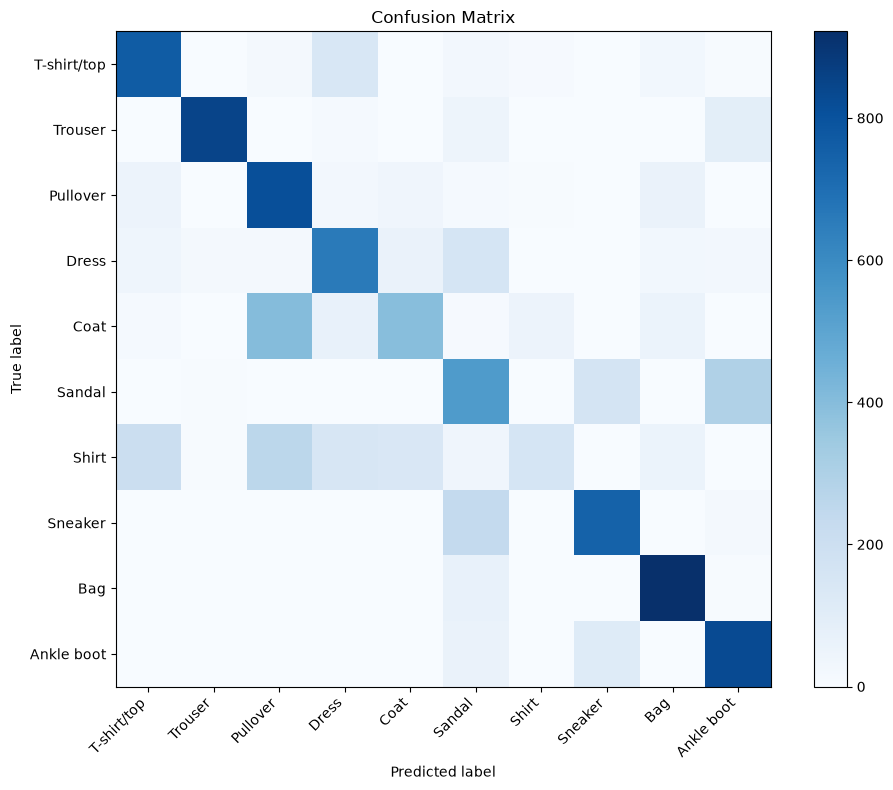

In [ ]:
baseline_accuracy = accuracy_score(y_true, y_pred)

print(
    f"Change from baseline: "
    f"{(improved_accuracy - baseline_accuracy) * 100:+.2f} percentage points"
)

improved_cm = confusion_matrix(
    y_true_improved,
    y_pred_improved,
    labels=range(len(CLASS_NAMES)),
)
print("Improved-prompt confusion matrix:")
print(improved_cm)

plot_confusion_matrix(y_true_improved, y_pred_improved, CLASS_NAMES)

Reflection: How did your detailed prompts affect the zero-shot classification performance? Did you see a significant improvement compared to the baseline? What insights did you gain about the model's understanding of the classes? Do you think that with more effort you could further improve the performance? If so, how?

Change from baseline: +4.24 percentage points, Improved-prompt confusion matrix ( see results above)

The detailed prompts improved zero-shot accuracy by 4.24 percentage points compared with the simple class-name baseline. This is a clear improvement in my experiment, though I would need a statistical test to determine whether the gain is statistically significant.

The result suggests that CLIP benefits from descriptive context, especially when prompts name visual or functional traits instead of relying on a short category label. The confusion matrix also helped me see which classes the model still mixed up. Categories with similar shapes or uses—such as shirts, pullovers, and coats—can be difficult to separate in Fashion-MNIST’s small grayscale images.

I could try more prompt variations, use several descriptions per class and average their embeddings, or make prompts more specific to the classes that remain confused. I could also compare a different pretrained vision–language model or test preprocessing changes. To keep the final evaluation fair, I would choose prompts using a validation set and reserve the test set for the final comparison.


## Visualizing Image Embeddings with UMAP

To better understand how the model perceives the different classes, we can visualize the image embeddings using UMAP (Uniform Manifold Approximation and Projection). UMAP is a dimensionality reduction technique that helps us see how similar or dissimilar the embeddings are in a lower-dimensional space.

By visualizing the embeddings, we can gain insights into how well the model can distinguish certain images, even without considering the text prompts. This can help us identify clusters of similar images and see if there are any overlaps between classes.

You should:

- [ ] Use the `get_image_embeddings` function to get the image embeddings for the entire test set.
- [ ] Use UMAP to reduce the dimensionality of the image embeddings to 2D.
- [ ] Plot the 2D embeddings, coloring each point by its true class label.

You may need to install the `umap-learn` library if you haven't already. You can do this by running `pip install umap-learn`.

In [ ]:
# Uncomment the following line to install UMAP if you haven't already
%pip install umap-learn

Note: you may need to restart the kernel to use updated packages.


c:\Users\usd01056\Documents\GitHub\deep_learning\deep-learning-env\Scripts\python.exe: No module named pip


In [ ]:
import os

os.environ["NUMBA_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

In [ ]:
from umap import UMAP

In [ ]:
from umap import UMAP

# ------------------------------------------------------------
# 1. Collect image embeddings
# ------------------------------------------------------------
all_img_emb = []
all_labels  = []

for pixel_values, labels in test_loader:


# ------------------------------------------------------------
# 2. Fit UMAP
# ------------------------------------------------------------


# ------------------------------------------------------------
# 3. Plot coloured by ground-truth label
# ------------------------------------------------------------


The UMAP embeddings allow us to see how separable or non-separable different classes are with our specific model. If two specific images are very similar, then they will be placed near each other on this graph. 

Reflection: Do you notice any challenges in distinguishing images based on this figure? Are there any types of clothing in the dataset which the model has no trouble distinguishing from the others?

## Mini-Experiment

In this section, you will conduct a mini-experiment of your choice to further explore the capabilities of zero-shot classification with transformers. This can be anything you'd like, but here are some ideas to get you started.

### A. Alternative Model

So far we have been utilizing OpenAI's CLIP model for zero-shot classification. However, there are many other vision–language models available in the `transformers` library that you can experiment with. For example, there are larger CLIP models such as [clip-vit-large-patch14](https://huggingface.co/openai/clip-vit-large-patch14), and open-source versions such as [laion/CLIP-ViT-B-32-laion2B-s34B-b79K](https://huggingface.co/laion/CLIP-ViT-B-32-laion2B-s34B-b79K). You can also search huggingface [here](https://huggingface.co/models?sort=trending&search=clip) to find other models that might be suitable for zero-shot classification.

You can try using a different model to see if it improves the zero-shot classification performance. You should:
- [ ] Load a different model and processor from the `transformers` library.
- [ ] Run the zero-shot classification baseline with the new model and report the accuracy and confusion matrix.
- [ ] Reflect on the performance of the new model compared to the original CLIP model
  - How does the new model perform compared to the original CLIP model?
  - Do you notice any differences in the types of errors made by the new model?

### B. Multiple-Description Classification

Another interesting experiment is to explore multiple-description classification. *This involves providing multiple text prompts for each class, allowing the model to choose the most relevant one. For example, instead of just "T-shirt/top", you could provide "a photo of a T-shirt", "a photo of a top", and "a photo of a shirt". This can help the model better understand the class and increases the likelihood of a correct prediction. You should:

- [ ] Create a list of multiple prompts for each class.
- [ ] Use the `get_text_embeddings` function to create text embeddings for the multiple prompts.
- [ ] Run the zero-shot classification baseline again using the multiple prompts and report the accuracy and confusion matrix.
- [ ] Consider the model to be correct if it guesses *any* of the prompts belonging to the correct class.

### C. Top-K Classification

In some classification tasks, it can be useful to consider if the right answer is among the top K (e.g. top 3) predictions. This can be particularly useful in cases where the model is uncertain or when there are multiple similar classes. You should:

- [ ] Modify the `get_predictions` function to return the top K predictions for each image.
- [ ] Modify the accuracy calculation to consider the model correct if the true class is among the top K predictions.
- [ ] Report the accuracy and confusion matrix for the top K predictions. Report at least two different values of K (e.g. K=2 and K=4).

### D. Other Ideas

You are welcome to come up with your own mini-experiment! Explain your idea in the report and implement it. Did it work as you expected? What did you learn from it?

In [11]:
#I tested whether CLIP’s zero-shot classification changes when each Fashion-MNIST class has several possible text descriptions. 
# I wrote three prompts for each class, embedded the prompts, and compared them with each image embedding. # I grouped the similarity scores by class and used the highest score among each class’s three prompts as that class’s score.I used the same number of prompts for every class
# I need to be mindful of the memory usage when running UMAP on large datasets with my laptop. If you encounter memory issues, consider using a smaller subset of the dataset or reducing the number of neighbors in UMAP.
# The confusion matrix showed that the model still confused
# This experiment showed me that CLIP’s predictions can depend on how a class is described. Using multiple descriptions gives the model more wording options, but it does not guarantee higher accuracy. The confusion matrix helped identify where prompt wording may need more careful distinctions.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/17/2026`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb)
    * The Lab 4 notebook (labs/lab_4.ipynb)
    * The Lab 5 notebook (labs/lab_5.ipynb)
    * The Lab 6 notebook (labs/lab_6.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.